# Tweakable Manuscript Plots

This notebook mirrors `make_figures.py` but separates work into two stages:
1. **Data prep**: load triplicate CV runs and compute final plotting values (run-level mean ± SE).
2. **Plotting**: consume only final values and render figures.

In [ ]:
from pathlib import Path
import ast
import json

import matplotlib.pyplot as plt
import numpy as np

# Paths
cwd = Path.cwd().resolve()
if (cwd / 'runs').exists() and (cwd / 'manuscript').exists():
    ROOT = cwd
elif cwd.name == 'scripts' and cwd.parent.name == 'manuscript':
    ROOT = cwd.parents[1]
else:
    raise RuntimeError(f'Could not infer repo root from cwd={cwd}')

# BERT_RUNS = [
#     ROOT / 'runs/cycpept_pampa_random5_cv_bertonly_20260506_no10_no8_no4_measurementlevel_e20',
#     ROOT / 'runs/cycpept_pampa_random5_cv_bertonly_20260506_no10_no8_no4_measurementlevel_e20_rep2',
#     ROOT / 'runs/cycpept_pampa_random5_cv_bertonly_20260506_no10_no8_no4_measurementlevel_e20_rep3',
# ]

# RANDOMINIT_RUNS = [
#     ROOT / 'runs/cycpept_pampa_random5_cv_hypermpnn_20260506_no10_no8_no4_randominit_h448_e20',
#     ROOT / 'runs/cycpept_pampa_random5_cv_hypermpnn_20260506_no10_no8_no4_randominit_h448_e20_rep2',
#     ROOT / 'runs/cycpept_pampa_random5_cv_hypermpnn_20260506_no10_no8_no4_randominit_h448_e20_rep3',
# ]

# PEPHGNN_RUNS = [
#     ROOT / 'runs/cycpept_pampa_random5_cv_hypermpnn_20260506_no10_no8_no4_oldpretrain_mlmv1_measurementlevel_e20',
#     ROOT / 'runs/cycpept_pampa_random5_cv_hypermpnn_20260506_no10_no8_no4_oldpretrain_mlmv1_measurementlevel_e20_rep2',
#     ROOT / 'runs/cycpept_pampa_random5_cv_hypermpnn_20260506_no10_no8_no4_oldpretrain_mlmv1_measurementlevel_e20_rep3',
# ]

# HYBRID_RUNS = [
#     ROOT / 'runs/cycpept_pampa_random5_cv_hybrid_20260427_no10_no8_no4_measurementlevel',
#     ROOT / 'runs/cycpept_pampa_random5_cv_hybrid_20260427_no10_no8_no4_measurementlevel_rep2',
#     ROOT / 'runs/cycpept_pampa_random5_cv_hybrid_20260427_no10_no8_no4_measurementlevel_rep3',
# ]

PRETRAIN_LOG = ROOT / 'logs/pretrain_allatom_481.out'
FIG_DIR = ROOT / 'manuscript/figures'

# Colors
COLOR_BERT = '#D17C2F'
COLOR_PEPHGNN = '#6BAED6'
COLOR_HYBRID = '#08519C'
COLOR_RANDOM = '#808080'


In [4]:
def load_json(path: Path):
    with path.open('r', encoding='utf-8') as fh:
        return json.load(fh)


def read_predictions(run_dir: Path):
    targets = []
    preds = []

    candidate_paths = []
    candidate_paths.extend(sorted(run_dir.glob('holdout_*_val_*/predictions.jsonl')))
    candidate_paths.extend(sorted(run_dir.glob('holdout_*/val_*/predictions.jsonl')))
    candidate_paths.extend(sorted(run_dir.glob('holdout_*/val_*/test_predictions.jsonl')))

    seen = set()
    for pred_path in candidate_paths:
        if pred_path in seen or not pred_path.exists():
            continue
        seen.add(pred_path)
        with pred_path.open('r', encoding='utf-8') as fh:
            for line in fh:
                row = json.loads(line)
                targets.append(float(row['target']))
                preds.append(float(row['prediction']))

    if not targets:
        raise RuntimeError(f'No predictions found in {run_dir}')

    return np.asarray(targets), np.asarray(preds)


def r2_score(y_true, y_pred):
    y_true_mean = np.mean(y_true)
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - y_true_mean) ** 2)
    return 1.0 - (ss_res / ss_tot)


def rmse(y_true, y_pred):
    return float(np.sqrt(np.mean((y_true - y_pred) ** 2)))


def load_cv_metrics(run_dirs):
    return [load_json(run_dir / 'cv_metrics.json') for run_dir in run_dirs]


def run_level_metric_summary(metrics_list):
    n_reps = len(metrics_list)
    if n_reps == 0:
        raise RuntimeError('No metrics provided')

    summary = {'n_reps': n_reps, 'n': int(metrics_list[0]['overall']['n'])}
    for key in ['r2', 'pearson_r', 'mae', 'rmse']:
        vals = np.asarray([float(m['overall'][key]) for m in metrics_list], dtype=float)
        summary[key] = float(np.mean(vals))
        summary[f'{key}_se'] = float(np.std(vals, ddof=1) / np.sqrt(n_reps)) if n_reps > 1 else 0.0
    return summary


def fold_r2_run_summary(metrics_list):
    folds = sorted(metrics_list[0]['holdout_metrics'].keys(), key=int)
    mat = np.asarray(
        [[float(m['holdout_metrics'][f]['r2']) for f in folds] for m in metrics_list],
        dtype=float,
    )
    means = np.mean(mat, axis=0)
    ses = np.std(mat, axis=0, ddof=1) / np.sqrt(len(metrics_list)) if len(metrics_list) > 1 else np.zeros_like(means)
    labels = [f'Fold {f}' for f in folds]
    return labels, means, ses


def moving_average(values, window=25):
    values = np.asarray(values, dtype=float)
    if window <= 1 or values.size < window:
        return values
    kernel = np.ones(window, dtype=float) / float(window)
    return np.convolve(values, kernel, mode='valid')


def parse_pretrain_log(log_path: Path):
    if not log_path.exists():
        raise FileNotFoundError(f'Pretraining log not found: {log_path}')

    train_steps = []
    train_total = []
    val_steps = []
    val_total = []
    train_steps_total_by_epoch = {}

    with log_path.open('r', encoding='utf-8') as fh:
        for raw in fh:
            line = raw.strip()
            if not line.startswith("{'phase':") or not line.endswith('}'):
                continue
            try:
                row = ast.literal_eval(line)
            except (ValueError, SyntaxError):
                continue

            if not isinstance(row, dict) or 'phase' not in row:
                continue

            epoch = int(row.get('epoch', 1))
            step = int(row.get('step', 0))
            steps_total = int(row.get('steps_total', 0))

            if row['phase'] == 'train' and 'train_total' in row:
                if steps_total > 0 and epoch not in train_steps_total_by_epoch:
                    train_steps_total_by_epoch[epoch] = steps_total
                global_step = step if steps_total <= 0 else (epoch - 1) * steps_total + step
                train_steps.append(float(global_step))
                train_total.append(float(row['train_total']))
            elif row['phase'] == 'val' and 'val_total' in row:
                if train_steps_total_by_epoch:
                    if epoch in train_steps_total_by_epoch:
                        train_epoch_total = train_steps_total_by_epoch[epoch]
                    else:
                        train_epoch_total = int(np.median(list(train_steps_total_by_epoch.values())))
                else:
                    train_epoch_total = steps_total

                if steps_total > 0 and train_epoch_total > 0:
                    frac = step / float(steps_total)
                    global_step = (epoch - 1) * train_epoch_total + frac * train_epoch_total
                else:
                    global_step = step if train_epoch_total <= 0 else (epoch - 1) * train_epoch_total + step

                val_steps.append(float(global_step))
                val_total.append(float(row['val_total']))

    if not train_steps and not val_steps:
        raise RuntimeError(f'No train/val loss records parsed from {log_path}')

    return {
        'train_steps': np.asarray(train_steps, dtype=float),
        'train_total': np.asarray(train_total, dtype=float),
        'val_steps': np.asarray(val_steps, dtype=float),
        'val_total': np.asarray(val_total, dtype=float),
    }

In [ ]:
# # Data prep: compute final values that plotting cells will consume.
# bert_metrics_runs = load_cv_metrics(BERT_RUNS)
# pephgnn_metrics_runs = load_cv_metrics(PEPHGNN_RUNS)
# hybrid_metrics_runs = load_cv_metrics(HYBRID_RUNS)
# random_metrics_runs = load_cv_metrics(RANDOMINIT_RUNS)

# agglomerated_data = {
#     "bert": bert_metrics_runs,
#     "pephgnn": pephgnn_metrics_runs,
#     "hybrid": hybrid_metrics_runs,
#     "random": random_metrics_runs
# }

# output_file = FIG_DIR / "cv_metrics.json"

# # write file
# with output_file.open("w", encoding="utf-8") as fh:
#     json.dump(agglomerated_data, fh, indent=4)


In [ ]:
# load JSON
input_file = FIG_DIR / "cv_metrics.json"

with input_file.open("r", encoding="utf-8") as fh:
    loaded_data = json.load(fh)

#Unpack to individual variables
bert_metrics_runs = loaded_data["bert"]
pephgnn_metrics_runs = loaded_data["pephgnn"]
hybrid_metrics_runs = loaded_data["hybrid"]
random_metrics_runs = loaded_data["random"]

bert_summary = run_level_metric_summary(bert_metrics_runs)
pephgnn_summary = run_level_metric_summary(pephgnn_metrics_runs)
hybrid_summary = run_level_metric_summary(hybrid_metrics_runs)
random_summary = run_level_metric_summary(random_metrics_runs)

fold_labels, bert_fold_mean, bert_fold_se = fold_r2_run_summary(bert_metrics_runs)
_, pephgnn_fold_mean, pephgnn_fold_se = fold_r2_run_summary(pephgnn_metrics_runs)
_, hybrid_fold_mean, hybrid_fold_se = fold_r2_run_summary(hybrid_metrics_runs)
_, random_fold_mean, random_fold_se = fold_r2_run_summary(random_metrics_runs)

geom_compare_summaries = {
    label: run_level_metric_summary(load_cv_metrics(run_dirs))
    for label, run_dirs in GEOM_COMPARE_RUNS.items()
}

# Scatter/residuals use the first run as the point-level diagnostic view.
bert_y, bert_p = read_predictions(BERT_RUNS[0])
pephgnn_y, pephgnn_p = read_predictions(PEPHGNN_RUNS[0])
hybrid_y, hybrid_p = read_predictions(HYBRID_RUNS[0])
random_y, random_p = read_predictions(RANDOMINIT_RUNS[0])

FINAL_VALUES = {
    'labels': ['R2', 'Pearson r', 'MAE', 'RMSE'],
    'overall_bars': {
        'Random-init': {
            'means': [
                random_summary['r2'],
                random_summary['pearson_r'],
                random_summary['mae'],
                random_summary['rmse'],
            ],
            'se': [
                random_summary['r2_se'],
                random_summary['pearson_r_se'],
                random_summary['mae_se'],
                random_summary['rmse_se'],
            ],
            'color': COLOR_RANDOM,
        },
        'BERT-only': {
            'means': [
                bert_summary['r2'],
                bert_summary['pearson_r'],
                bert_summary['mae'],
                bert_summary['rmse'],
            ],
            'se': [
                bert_summary['r2_se'],
                bert_summary['pearson_r_se'],
                bert_summary['mae_se'],
                bert_summary['rmse_se'],
            ],
            'color': COLOR_BERT,
        },
        'EnsembleEGNN': {
            'means': [
                pephgnn_summary['r2'],
                pephgnn_summary['pearson_r'],
                pephgnn_summary['mae'],
                pephgnn_summary['rmse'],
            ],
            'se': [
                pephgnn_summary['r2_se'],
                pephgnn_summary['pearson_r_se'],
                pephgnn_summary['mae_se'],
                pephgnn_summary['rmse_se'],
            ],
            'color': COLOR_PEPHGNN,
        },
        'Hybrid': {
            'means': [
                hybrid_summary['r2'],
                hybrid_summary['pearson_r'],
                hybrid_summary['mae'],
                hybrid_summary['rmse'],
            ],
            'se': [
                hybrid_summary['r2_se'],
                hybrid_summary['pearson_r_se'],
                hybrid_summary['mae_se'],
                hybrid_summary['rmse_se'],
            ],
            'color': COLOR_HYBRID,
        },
    },
    'fold_r2': {
        'fold_labels': fold_labels,
        'Random-init': {'means': random_fold_mean.tolist(), 'se': random_fold_se.tolist(), 'color': COLOR_RANDOM},
        'BERT-only': {'means': bert_fold_mean.tolist(), 'se': bert_fold_se.tolist(), 'color': COLOR_BERT},
        'EnsembleEGNN': {'means': pephgnn_fold_mean.tolist(), 'se': pephgnn_fold_se.tolist(), 'color': COLOR_PEPHGNN},
        'Hybrid': {'means': hybrid_fold_mean.tolist(), 'se': hybrid_fold_se.tolist(), 'color': COLOR_HYBRID},
    },
    'scatter': {
        'Random-init': {'y_true': random_y, 'y_pred': random_p, 'color': COLOR_RANDOM},
        'BERT-only': {'y_true': bert_y, 'y_pred': bert_p, 'color': COLOR_BERT},
        'EnsembleEGNN': {'y_true': pephgnn_y, 'y_pred': pephgnn_p, 'color': COLOR_PEPHGNN},
        'Hybrid': {'y_true': hybrid_y, 'y_pred': hybrid_p, 'color': COLOR_HYBRID},
    },
    'residuals': {
        'Random-init': {'values': (random_p - random_y), 'color': COLOR_RANDOM},
        'BERT-only': {'values': (bert_p - bert_y), 'color': COLOR_BERT},
        'EnsembleEGNN': {'values': (pephgnn_p - pephgnn_y), 'color': COLOR_PEPHGNN},
        'Hybrid': {'values': (hybrid_p - hybrid_y), 'color': COLOR_HYBRID},
    },
}

GEOM_COMPARE_VALUES = {
    'labels': list(GEOM_COMPARE_RUNS.keys()),
    'metric_order': ['r2', 'pearson_r', 'mae', 'rmse'],
    'metric_labels': {'r2': 'R2', 'pearson_r': 'Pearson r', 'mae': 'MAE', 'rmse': 'RMSE'},
    'summaries': geom_compare_summaries,
    'colors': GEOM_COMPARE_COLORS,
}

print('Prepared FINAL_VALUES for plotting with triplicate random-init, pretrained, BERT, and hybrid runs.')
print('Main figure set: Random-init h448 e20 triplicate | BERT e20 triplicate | EnsembleEGNN old-pretrain e20 triplicate | Hybrid e20 triplicate')
print('Geometric comparison: all geometric conditions below are now triplicate runs.')
for label, summary in GEOM_COMPARE_VALUES['summaries'].items():
    print(
        f"{label}: R2={summary['r2']:.3f}, Pearson r={summary['pearson_r']:.3f}, "
        f"MAE={summary['mae']:.3f}, RMSE={summary['rmse']:.3f}, n_reps={summary['n_reps']}"
    )

Prepared FINAL_VALUES for plotting with triplicate random-init, pretrained, BERT, and hybrid runs.
Main figure set: Random-init h448 e20 triplicate | BERT e20 triplicate | EnsembleEGNN old-pretrain e20 triplicate | Hybrid e20 triplicate
Geometric comparison: all geometric conditions below are now triplicate runs.
Random init h448 (n=3): R2=0.005, Pearson r=0.113, MAE=0.457, RMSE=0.601, n_reps=3
Old pretrain (n=3): R2=0.477, Pearson r=0.699, MAE=0.319, RMSE=0.436, n_reps=3
Mask25 + coord-only (n=3): R2=0.465, Pearson r=0.683, MAE=0.318, RMSE=0.441, n_reps=3


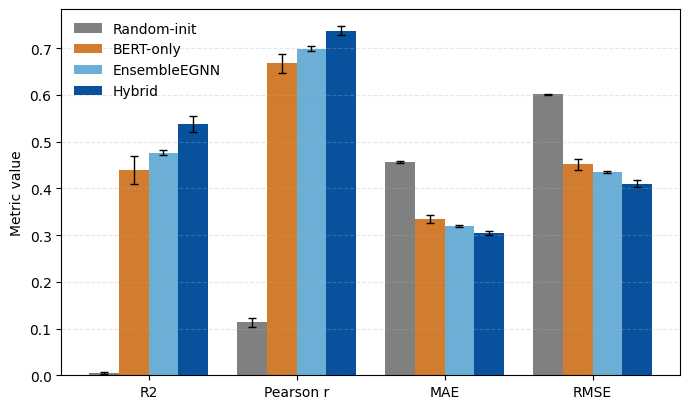

In [7]:
# Plot 1: Overall bars with run-level SE
plot_order = ['Random-init', 'BERT-only', 'EnsembleEGNN', 'Hybrid']
labels = FINAL_VALUES['labels']
x = np.arange(len(labels))
width = 0.20

fig, ax = plt.subplots(figsize=(7, 4.2))
err_kw = {'elinewidth': 1.0, 'capsize': 3, 'capthick': 1.0}

for i, model in enumerate(plot_order):
    offset = (i - (len(plot_order) - 1) / 2) * width
    model_vals = FINAL_VALUES['overall_bars'][model]
    ax.bar(
        x + offset,
        model_vals['means'],
        yerr=model_vals['se'],
        width=width,
        label=model,
        color=model_vals['color'],
        error_kw=err_kw,
    )

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('Metric value')
ax.set_title('')
ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / 'cv_overall_metrics.png', dpi=300)
plt.show()

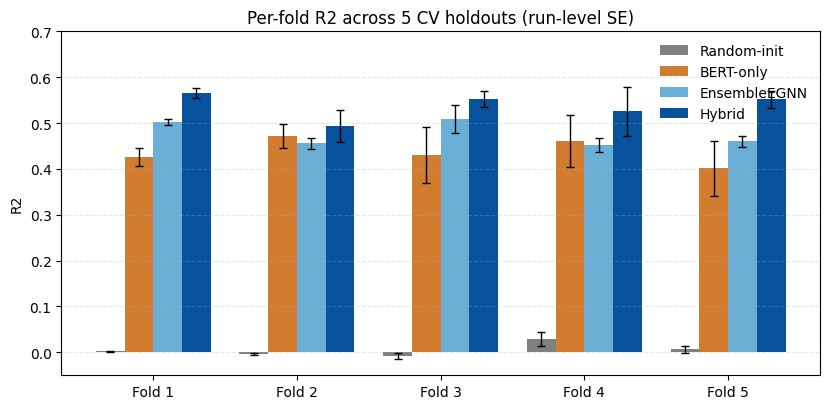

In [65]:
# Plot 2: Fold-wise R2 bars with run-level SE
fold_vals = FINAL_VALUES['fold_r2']
plot_order = ['Random-init', 'BERT-only', 'EnsembleEGNN', 'Hybrid']
x = np.arange(len(fold_vals['fold_labels']))
width = 0.20

fig, ax = plt.subplots(figsize=(8.4, 4.2))
err_kw = {'elinewidth': 1.0, 'capsize': 3, 'capthick': 1.0}
for i, model in enumerate(plot_order):
    offset = (i - (len(plot_order) - 1) / 2) * width
    ax.bar(
        x + offset,
        fold_vals[model]['means'],
        yerr=fold_vals[model]['se'],
        width=width,
        label=model,
        color=fold_vals[model]['color'],
        error_kw=err_kw,
    )

ax.set_xticks(x)
ax.set_xticklabels(fold_vals['fold_labels'])
ax.set_ylabel('R2')
ax.set_ylim(-0.05, 0.70)
ax.set_title('Per-fold R2 across 5 CV holdouts (run-level SE)')
ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / 'cv_fold_r2.png', dpi=300)
plt.show()

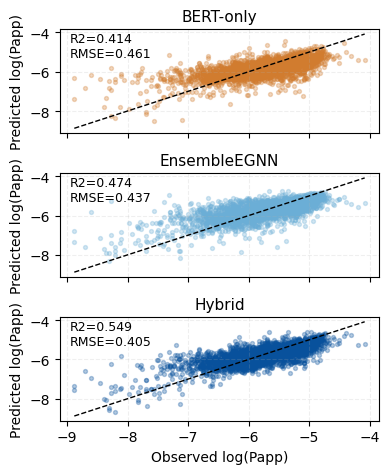

In [80]:
# Plot 3: Prediction scatter
scatter_vals = FINAL_VALUES['scatter']
plot_order = ['BERT-only', 'EnsembleEGNN', 'Hybrid']

lo = min(
    *(float(np.min(scatter_vals[model]['y_true'])) for model in plot_order),
    *(float(np.min(scatter_vals[model]['y_pred'])) for model in plot_order),
)
hi = max(
    *(float(np.max(scatter_vals[model]['y_true'])) for model in plot_order),
    *(float(np.max(scatter_vals[model]['y_pred'])) for model in plot_order),
)

fig, axes = plt.subplots(len(plot_order), 1, figsize=(4, 5), sharex=True, sharey=True)

for ax, model in zip(axes, plot_order):
    y_true = scatter_vals[model]['y_true']
    y_pred = scatter_vals[model]['y_pred']
    ax.scatter(y_true, y_pred, s=8, alpha=0.3, color=scatter_vals[model]['color'])
    ax.plot([lo, hi], [lo, hi], linestyle='--', color='black', linewidth=1)
    ax.set_title(model, fontsize=11)
    ax.set_ylabel('Predicted log(Papp)', fontsize=10)
    ax.grid(linestyle='--', alpha=0.2)
    ax.text(
        0.03,
        0.97,
        f"R2={r2_score(y_true, y_pred):.3f}\nRMSE={rmse(y_true, y_pred):.3f}",
        transform=ax.transAxes,
        va='top',
        ha='left',
        fontsize=9,
    )

axes[-1].set_xlabel('Observed log(Papp)', fontsize=10)
fig.suptitle('')
fig.tight_layout()
fig.savefig(FIG_DIR / 'cv_parity.png', dpi=300, bbox_inches='tight')
plt.show()

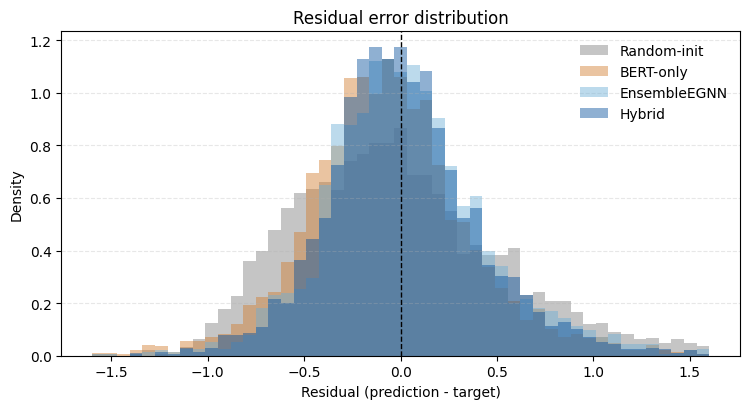

In [67]:
# Plot 4: Residual distributions
resid_vals = FINAL_VALUES['residuals']
bins = np.linspace(-1.6, 1.6, 50)

fig, ax = plt.subplots(figsize=(7.6, 4.2))
for model in ['Random-init', 'BERT-only', 'EnsembleEGNN', 'Hybrid']:
    ax.hist(
        resid_vals[model]['values'],
        bins=bins,
        alpha=0.45,
        label=model,
        color=resid_vals[model]['color'],
        density=True,
    )

ax.axvline(0.0, linestyle='--', linewidth=1, color='black')
ax.set_xlabel('Residual (prediction - target)')
ax.set_ylabel('Density')
ax.set_title('Residual error distribution')
ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / 'cv_residuals.png', dpi=300)
plt.show()

## Pretraining Loss Curve

This section parses pretraining stdout logs (printed dict records) and plots train/validation total loss versus global step.

- Default source is `PRETRAIN_LOG` from Cell 2.
- Change `PRETRAIN_LOG` to any file in `logs/pretrain*.out` and re-run this cell.

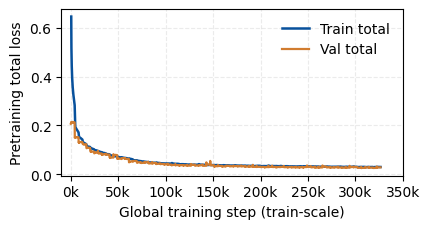

Parsed log: /novo/users/arvf/peptide-ensemble-mpnn/logs/pretrain_allatom_481.out
Train points: 32720 | Val points: 3600


In [69]:
# Plot 5: Pretraining loss curve (from pretraining stdout log)
loss_data = parse_pretrain_log(PRETRAIN_LOG)

train_steps = loss_data['train_steps']
train_total = loss_data['train_total']
val_steps = loss_data['val_steps']
val_total = loss_data['val_total']

fig, ax = plt.subplots(figsize=(4.4, 2.4))

if train_steps.size > 0:
    smooth_window = 50
    train_smooth = moving_average(train_total, window=smooth_window)
    if train_smooth.size != train_total.size:
        train_smooth_x = train_steps[smooth_window - 1:]
    else:
        train_smooth_x = train_steps
    ax.plot(train_smooth_x, train_smooth, color=COLOR_HYBRID, linewidth=1.8, label='Train total')

if val_steps.size > 0:
    ax.plot(val_steps, val_total, color=COLOR_BERT, linewidth=1.6, label='Val total')

# Keep x-axis non-negative and format ticks as k-steps.
ax.set_xlim(left=0)
xticks = ax.get_xticks()
xticks = [x for x in xticks if x >= 0]
ax.set_xticks(xticks)
ax.set_xticklabels([f'{x/1000:.0f}k' for x in xticks])

# set x min to -10 to give some padding for the first point if it starts at 0.
ax.set_xlim(left=-10000)

ax.set_xlabel('Global training step (train-scale)')
ax.set_ylabel('Pretraining total loss')
ax.set_title('')
ax.grid(axis='both', linestyle='--', alpha=0.25)
ax.legend(frameon=False, ncol=1, loc='best')
fig.tight_layout()
fig.savefig(FIG_DIR / 'pretrain_loss_curve.png', dpi=300)
plt.show()

print(f'Parsed log: {PRETRAIN_LOG}')
print(f'Train points: {train_steps.size} | Val points: {val_steps.size}')